<div class="alert">

### Exercise : The Classic Iris Dataset

Three species of the iris plant are iris setosa, iris versicolor and iris virginica. 50 samples of each species are collected, then the length and width of their flower petals are measured. This data is stored in a file named `iris_train.csv`. Each line has petal length, petal width and species name separated by commas. 

a)	Use `sklearn` and 5-fold cross-validation to output the optimal value of k in kNN for the data in `iris_train.csv`, then calculate the accuracy with the following test data:
    
|Petal Length|Petal Width|Species|
|-|-|-|
|1.5|0.2|Setosa|
|1.2|0.2|Setosa|
|4.3|1.3|Versicolor|
|4.1|1.3|Versicolor|
|5.6|2.1|Virginica|

</div>

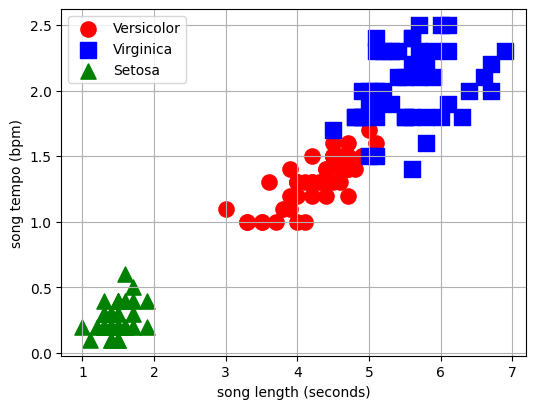

In [1]:
import numpy as np
from ml_lib import *
features = np.loadtxt("iris_train.csv", delimiter=",", usecols=(0,1))
labels = np.loadtxt("iris_train.csv", str, delimiter=",", usecols=(2))
plot_labelled_data(features, labels)


In [2]:
from sklearn.neighbors import KNeighborsClassifier
estimator = KNeighborsClassifier()

In [3]:
import numpy as np
from sklearn.model_selection import cross_val_score
k_fold = 5
max_k = int(len(features) * ((k_fold - 1) / k_fold) )# size of training data = (k_fold-1)/f_fold) * size_of_dataset
k_values = range(1, max_k+1)
k_scores =[]
for k in k_values:
    estimator.set_params(n_neighbors=k)
    k_scores.append(
        np.mean(
                cross_val_score(
                    estimator,
                    features,
                    labels,
                    cv=k_fold))
    )
best_k = k_values[k_scores.index(max(k_scores))]
print(f"Best k is {best_k}")
estimator.set_params(n_neighbors=best_k)
estimator.fit(features,labels)



Best k is 1


,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [4]:
## Using GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, KFold, RepeatedStratifiedKFold, GridSearchCV

cv = 5
max_k = int((cv - 1) / cv * len(features))
k_values = range(1,max_k+1)
# splitter = KFold(n_splits=cv,shuffle=True)
# splitter = StratifiedKFold(n_splits=cv,shuffle=True, random_state=42)
splitter = RepeatedStratifiedKFold(
    n_splits=cv, 
    n_repeats=5, 
    random_state=42)

param_grid = { 'n_neighbors':k_values}
grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv = splitter # Default uses StratifiedKFold(n_splits=cv, shuffle=False)
)
grid.fit(features, labels)

print(grid.best_params_)
print(grid.best_score_)

{'n_neighbors': 6}
0.9641379310344829


In [5]:
estimator.set_params(n_neighbors=best_k)
estimator.fit(features,labels)
for test_data in [
    (1.5,0.2,"Setosa"),
    (1.2,0.2,"Setosa"),
    (4.3,1.3,"Versicolor"),
    (4.1,1.3,"Versicolor"),
    (5.6,2.1,"Virginica")
]:
    print(est:=estimator.predict([test_data[:-1]]),
          est==test_data[-1])

['Setosa'] [ True]
['Setosa'] [ True]
['Versicolor'] [ True]
['Versicolor'] [ True]
['Virginica'] [ True]


<div class="alert">

b)	Discard the labels. Use `sklearn` to output the clustering of data in `iris_train.csv` (without the labels) into 3 groups with the lowest inertia out of 100 initial conditions.

</div>

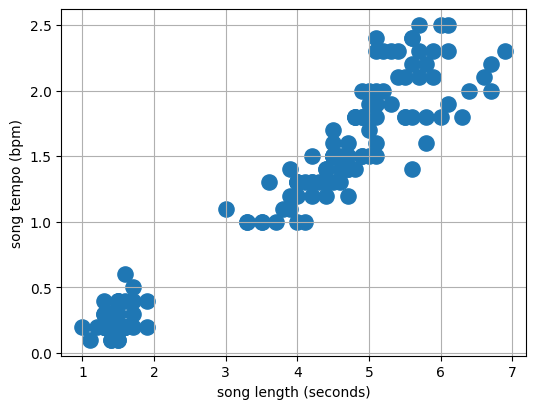

In [6]:
import numpy as np
from ml_lib import *
features = np.loadtxt("iris_train.csv", delimiter=",", usecols=(0,1))
plot_data(features)


In [7]:
from sklearn.cluster import KMeans
estimator = KMeans(n_clusters=4, n_init=100, max_iter=10)
estimator.fit(features)

,n_clusters,4
,init,'k-means++'
,n_init,100
,max_iter,10
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [8]:
import numpy as np
features = np.loadtxt("iris_train.csv", delimiter=",", usecols=(0,1))

estimator = KMeans(n_clusters=3, n_init=100)
estimator.fit(features)
print(estimator.labels_)
print(estimator.inertia_)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 0 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0
 0 0 0 0 2 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0]
31.25811790780142


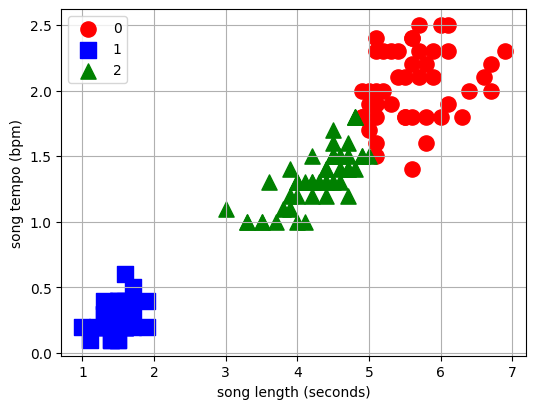

In [9]:
plot_labelled_data(features, estimator.labels_)